In [2]:
import pandas as pd

df = pd.read_csv('data.csv')

In [27]:
df['Permanent DI'].sum() / len(df) * 100

64.40677966101694

In [2]:
df.columns

Index(['Date', 'Age ', 'BMI', 'Surgical Approach',
       'Pre-op visual impairment (y/n) - symptomatic complaint of visual loss',
       'Pre-op hydrocephalus (y/n)', 'Pre-op intacranial pressure symptoms',
       'Pre-op headache', 'Pre-op endocrine changes (y/n)',
       'Pre-op panhypopit (y/n) - define number of hormone axes that are non-functional',
       'Axes disrupted', 'Tumor size', 'Tumor size.1', 'Tumor size.2',
       'Tumor volume', 'Tumor (Adamantinomatous, papillary)', 'BRAF+',
       'Location (purely intrasellar, suprasellar/sellar, suprasellar/sellar with pseudoventricular extension, suprasellar/sellar with intraventricular extension, purely intraventricular)',
       'Intraventricular extension', 'Solid, cystic, mixed',
       'Resection outcome (total, subtotal, partial)', 'Prior operation',
       'recurring tumor?', 'Recurrence after this operation',
       'Recurrence date', 'Days to recurrence',
       'Re-operation after this operation (add date)', 'Time to r

In [3]:
# === EDA for CP Permanent DI paper ===
# Generates cohort summaries and 300 dpi figures into ./figs/
import os
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Optional (nice styling). If seaborn not installed, comment it out.
import seaborn as sns
sns.set_context("talk")
sns.set_style("whitegrid")

# Optional missingness visualization
try:
    import missingno as msno
    HAS_MSNO = True
except Exception:
    HAS_MSNO = False

# -------------------------
# 0) Paths & constants
# -------------------------
DATA_PATH = "data.csv"
FIG_DIR = "figs"
os.makedirs(FIG_DIR, exist_ok=True)

# Column names used repeatedly (keep exact spellings)
COL_AGE = "Age "
COL_BMI = "BMI"
COL_LAST_BMI = "Last BMI on file"

COL_TS1 = "Tumor size"
COL_TS2 = "Tumor size.1"
COL_TS3 = "Tumor size.2"
COL_TVOL = "Tumor volume"

COL_VIS = "Pre-op visual impairment (y/n) - symptomatic complaint of visual loss"
COL_HCP = "Pre-op hydrocephalus (y/n)"
COL_ICP = "Pre-op intacranial pressure symptoms"
COL_HA  = "Pre-op headache"
COL_END = "Pre-op endocrine changes (y/n)"
COL_PAN = "Pre-op panhypopit (y/n) - define number of hormone axes that are non-functional"
COL_IVX = "Intraventricular extension"

COL_SAPP = "Surgical Approach"
COL_RO   = "Resection outcome (total, subtotal, partial)"

COL_SOLIDMIX = "Solid, cystic, mixed"
COL_LOC = "Location (purely intrasellar, suprasellar/sellar, suprasellar/sellar with pseudoventricular extension, suprasellar/sellar with intraventricular extension, purely intraventricular)"

COL_PERMDI = "Permanent DI"

# Convenience buckets
CONTINUOUS = [COL_AGE, COL_BMI, COL_LAST_BMI, COL_TS1, COL_TS2, COL_TS3, COL_TVOL]
BINARY = [COL_VIS, COL_HCP, COL_ICP, COL_HA, COL_END, COL_PAN, COL_IVX]
CATEGORICAL = [COL_SAPP, COL_RO, COL_SOLIDMIX, COL_LOC]

# -------------------------
# 1) Load & light cleaning
# -------------------------
df = pd.read_csv(DATA_PATH)

# Recompute tumor volume if missing or fully absent (ellipsoid)
if COL_TVOL not in df.columns:
    df[COL_TVOL] = np.nan

need = df[COL_TVOL].isna()
if all(c in df.columns for c in [COL_TS1, COL_TS2, COL_TS3]) and need.any():
    df.loc[need, COL_TVOL] = (4/3)*math.pi * (df.loc[need, COL_TS1]/2) * (df.loc[need, COL_TS2]/2) * (df.loc[need, COL_TS3]/2)

# Coerce numeric columns that might be object-typed
for c in [COL_AGE, COL_BMI, COL_LAST_BMI, COL_TS1, COL_TS2, COL_TS3, COL_TVOL]:
    if c in df.columns:
        df[c] = pd.to_numeric(df[c], errors="coerce")

# -------------------------
# 2) Cohort & outcome summary
# -------------------------
n = len(df)
n_with_outcome = df[COL_PERMDI].notna().sum()
prevalence = df[COL_PERMDI].mean() if n_with_outcome > 0 else np.nan

summary = pd.DataFrame({
    "N_total": [n],
    "N_outcome_nonmissing": [n_with_outcome],
    "Permanent_DI_prevalence": [prevalence]
})
summary.to_csv(os.path.join(FIG_DIR, "cohort_summary.csv"), index=False)
print(summary)

# Outcome prevalence figure
plt.figure(figsize=(4.5, 5))
vals = [df[COL_PERMDI].sum(), (df[COL_PERMDI]==0).sum()] if df[COL_PERMDI].notna().any() else [0,0]
labels = ["Permanent DI = 1", "Permanent DI = 0"]
plt.bar(labels, vals, color=["#4C78A8","#72B7B2"])
plt.ylabel("Count")
plt.title("Permanent DI Outcome Counts")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig_outcome_counts.png"), dpi=300)
plt.close()

# -------------------------
# 3) Missingness overview
# -------------------------
missing_counts = df.isna().sum().sort_values(ascending=False)
missing_counts.to_csv(os.path.join(FIG_DIR, "missing_counts.csv"))

plt.figure(figsize=(8, 10))
missing_counts.head(30).plot(kind="barh")
plt.gca().invert_yaxis()
plt.xlabel("Missing values")
plt.title("Missingness by feature (top 30)")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig_missing_counts.png"), dpi=300)
plt.close()

if HAS_MSNO:
    # Matrix view
    plt.figure(figsize=(10, 6))
    msno.matrix(df)
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, "fig_missing_matrix.png"), dpi=300)
    plt.close()

    # Heatmap of missingness correlations
    plt.figure(figsize=(8, 6))
    msno.heatmap(df)
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, "fig_missing_heatmap.png"), dpi=300)
    plt.close()

# -------------------------
# 4) Continuous distributions
# -------------------------
def hist_kde(series, name):
    s = series.dropna()
    if len(s) == 0: 
        return
    plt.figure(figsize=(6, 4.2))
    sns.histplot(s, bins=15, kde=True, edgecolor="black")
    plt.xlabel(name)
    plt.ylabel("Frequency")
    plt.title(f"Distribution of {name}")
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, f"fig_dist_{name.replace(' ','_')}.png"), dpi=300)
    plt.close()

for col in [c for c in CONTINUOUS if c in df.columns]:
    hist_kde(df[col], col)

# Correlation (continuous only)
cont_available = [c for c in CONTINUOUS if c in df.columns]
if len(cont_available) >= 2:
    corr = df[cont_available].corr(method="spearman", min_periods=1)
    plt.figure(figsize=(6.8, 5.6))
    sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", cbar_kws={"shrink": .8})
    plt.title("Spearman Correlation (Continuous Variables)")
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, "fig_corr_continuous.png"), dpi=300)
    plt.close()
    corr.to_csv(os.path.join(FIG_DIR, "corr_continuous.csv"))

# -------------------------
# 5) Categorical distributions
# -------------------------
def bar_counts(col):
    if col not in df.columns: 
        return
    vc = df[col].astype(str).str.strip().str.lower().value_counts(dropna=True)
    plt.figure(figsize=(7, 4.2))
    sns.barplot(x=vc.index, y=vc.values, color="#4C78A8")
    plt.ylabel("Count")
    plt.xlabel(col)
    plt.title(f"{col} (counts)")
    plt.xticks(rotation=25, ha="right")
    plt.tight_layout()
    fname = f"fig_counts_{col[:30].replace(' ','_')}.png"
    plt.savefig(os.path.join(FIG_DIR, fname), dpi=300)
    plt.close()

for col in [c for c in CATEGORICAL if c in df.columns]:
    bar_counts(col)

# -------------------------
# 6) Outcome-stratified plots
# -------------------------
# 6a) Continuous vs outcome: box/violin
def cont_vs_outcome(col):
    if col not in df.columns or COL_PERMDI not in df.columns:
        return
    sub = df[[col, COL_PERMDI]].dropna()
    if sub[COL_PERMDI].nunique() != 2:
        return
    sub[COL_PERMDI] = sub[COL_PERMDI].astype(int)

    plt.figure(figsize=(5.2, 4.6))
    sns.boxplot(x=COL_PERMDI, y=col, data=sub)
    sns.stripplot(x=COL_PERMDI, y=col, data=sub, color="black", alpha=0.4, jitter=0.15)
    plt.xlabel("Permanent DI (0/1)")
    plt.ylabel(col)
    plt.title(f"{col} by Permanent DI")
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, f"fig_{col.replace(' ','_')}_by_DI_box.png"), dpi=300)
    plt.close()

    plt.figure(figsize=(5.2, 4.6))
    sns.violinplot(x=COL_PERMDI, y=col, data=sub, inner="box")
    plt.xlabel("Permanent DI (0/1)")
    plt.ylabel(col)
    plt.title(f"{col} by Permanent DI (Violin)")
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, f"fig_{col.replace(' ','_')}_by_DI_violin.png"), dpi=300)
    plt.close()

for col in [c for c in CONTINUOUS if c in df.columns]:
    cont_vs_outcome(col)

# 6b) Categorical vs outcome: stacked bars (proportion within category)
def cat_vs_outcome(col):
    if col not in df.columns or COL_PERMDI not in df.columns:
        return
    sub = df[[col, COL_PERMDI]].dropna()
    if sub.empty or sub[COL_PERMDI].nunique() != 2: 
        return

    # normalize categories
    sub[col] = sub[col].astype(str).str.strip().str.lower()
    tab = pd.crosstab(sub[col], sub[COL_PERMDI], normalize="index")  # proportions per category

    # stacked bar
    plt.figure(figsize=(7.0, 4.5))
    bottom = np.zeros(len(tab))
    for di_val in sorted(tab.columns):
        plt.bar(tab.index, tab[di_val].values, bottom=bottom, label=f"DI={di_val}")
        bottom += tab[di_val].values
    plt.ylabel("Proportion within category")
    plt.xlabel(col)
    plt.title(f"Proportion of Permanent DI by {col}")
    plt.xticks(rotation=25, ha="right")
    plt.legend()
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, f"fig_DI_by_{col[:30].replace(' ','_')}_stacked.png"), dpi=300)
    plt.close()

# Apply to key categorical predictors
for col in [c for c in [COL_SAPP, COL_RO, COL_SOLIDMIX, COL_LOC] if c in df.columns]:
    cat_vs_outcome(col)

# -------------------------
# 7) One-page summary table (overall + by outcome)
# -------------------------
def summarize_by_outcome(df, continuous, binary, categorical, outcome):
    rows = []

    # Overall and by outcome
    for label, d in [("Overall", df), ("DI=0", df[df[outcome]==0]), ("DI=1", df[df[outcome]==1])]:
        if d.empty: 
            continue

        # Continuous
        for c in [x for x in continuous if x in d.columns]:
            s = d[c].dropna()
            rows.append({
                "Group": label,
                "Feature": c,
                "Type": "continuous",
                "N": len(s),
                "Mean": np.round(s.mean(), 3) if len(s) else np.nan,
                "SD": np.round(s.std(ddof=1), 3) if len(s) else np.nan,
                "Median": np.round(s.median(), 3) if len(s) else np.nan,
                "IQR": np.round((s.quantile(0.75)-s.quantile(0.25)), 3) if len(s) else np.nan
            })

        # Binary/categorical as counts
        for c in [x for x in binary + categorical if x in d.columns]:
            vc = d[c].value_counts(dropna=True)
            # count of 1 for binary; otherwise top categories
            if c in binary:
                n1 = int((d[c]==1).sum())
                n0 = int((d[c]==0).sum())
                rows.append({"Group": label, "Feature": c, "Type": "binary", "N": int(d[c].notna().sum()), "Count_1": n1, "Count_0": n0})
            else:
                # categorical
                topk = vc.head(5)
                desc = "; ".join([f"{idx}:{cnt}" for idx, cnt in topk.items()])
                rows.append({"Group": label, "Feature": c, "Type": "categorical", "N": int(d[c].notna().sum()), "Top5": desc})

    return pd.DataFrame(rows)

summary_tbl = summarize_by_outcome(df, CONTINUOUS, BINARY, CATEGORICAL, COL_PERMDI)
summary_tbl.to_csv(os.path.join(FIG_DIR, "summary_by_outcome.csv"), index=False)
print("Saved figures →", FIG_DIR)


   N_total  N_outcome_nonmissing  Permanent_DI_prevalence
0       59                    58                 0.655172


C:\Users\shrin\AppData\Local\Temp\ipykernel_34752\2446678096.py:114: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()
C:\Users\shrin\AppData\Local\Temp\ipykernel_34752\2446678096.py:122: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()
C:\Users\shrin\AppData\Local\Temp\ipykernel_34752\2446678096.py:129: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


Saved figures → figs


<Figure size 1000x600 with 0 Axes>

<Figure size 800x600 with 0 Axes>

In [29]:
df["Permanent DI"].sum() 

38.0

In [3]:
df["Recurrence after this operation"].sum()

17

In [4]:
df["Recurrence after this operation"].sum() / len(df) * 100

28.8135593220339

In [28]:
prevalence

0.6551724137931034

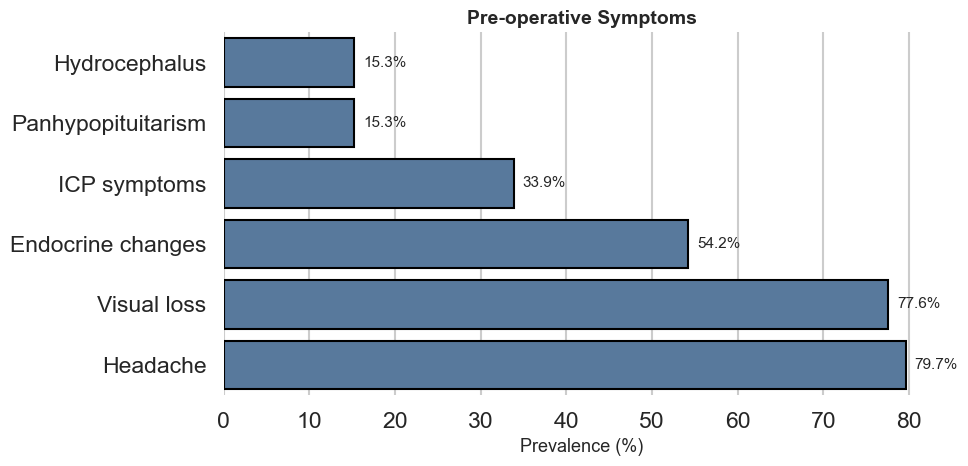

In [16]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

os.makedirs("figs", exist_ok=True)
sns.set_context("talk"); sns.set_style("whitegrid")

# Load
df = pd.read_csv("data.csv")

# Clinical symptoms only (no radiographic items)
symptom_map = {
    "Pre-op visual impairment (y/n) - symptomatic complaint of visual loss": "Visual loss",
    "Pre-op hydrocephalus (y/n)": "Hydrocephalus",
    "Pre-op intacranial pressure symptoms": "ICP symptoms",
    "Pre-op headache": "Headache",
    "Pre-op endocrine changes (y/n)": "Endocrine changes",
    "Pre-op panhypopit (y/n) - define number of hormone axes that are non-functional": "Panhypopituitarism",
}

# Calculate prevalence
rows = []
for col, label in symptom_map.items():
    if col in df.columns:
        n_total = df[col].notna().sum()
        n_pos = int((df[col] == 1).sum())
        perc = 100 * n_pos / n_total if n_total > 0 else 0.0
        rows.append({"Symptom": label, "Percent": perc, "n_pos": n_pos, "n_total": n_total})

symptom_df = pd.DataFrame(rows).sort_values("Percent", ascending=True)

# Plot
plt.figure(figsize=(10, 5.0))
sns.barplot(x="Percent", y="Symptom", data=symptom_df, color="#4C78A8", edgecolor="black")
for i, r in enumerate(symptom_df.itertuples()):
    plt.text(r.Percent + 1, i, f"{r.Percent:.1f}%", va="center", fontsize=11)

plt.xlabel("Prevalence (%)", fontsize=13)
plt.ylabel("")
plt.title("Pre-operative Symptoms", fontsize=14, weight="bold")
sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.savefig("figs/fig_preop_symptoms.png", dpi=300)
plt.show()


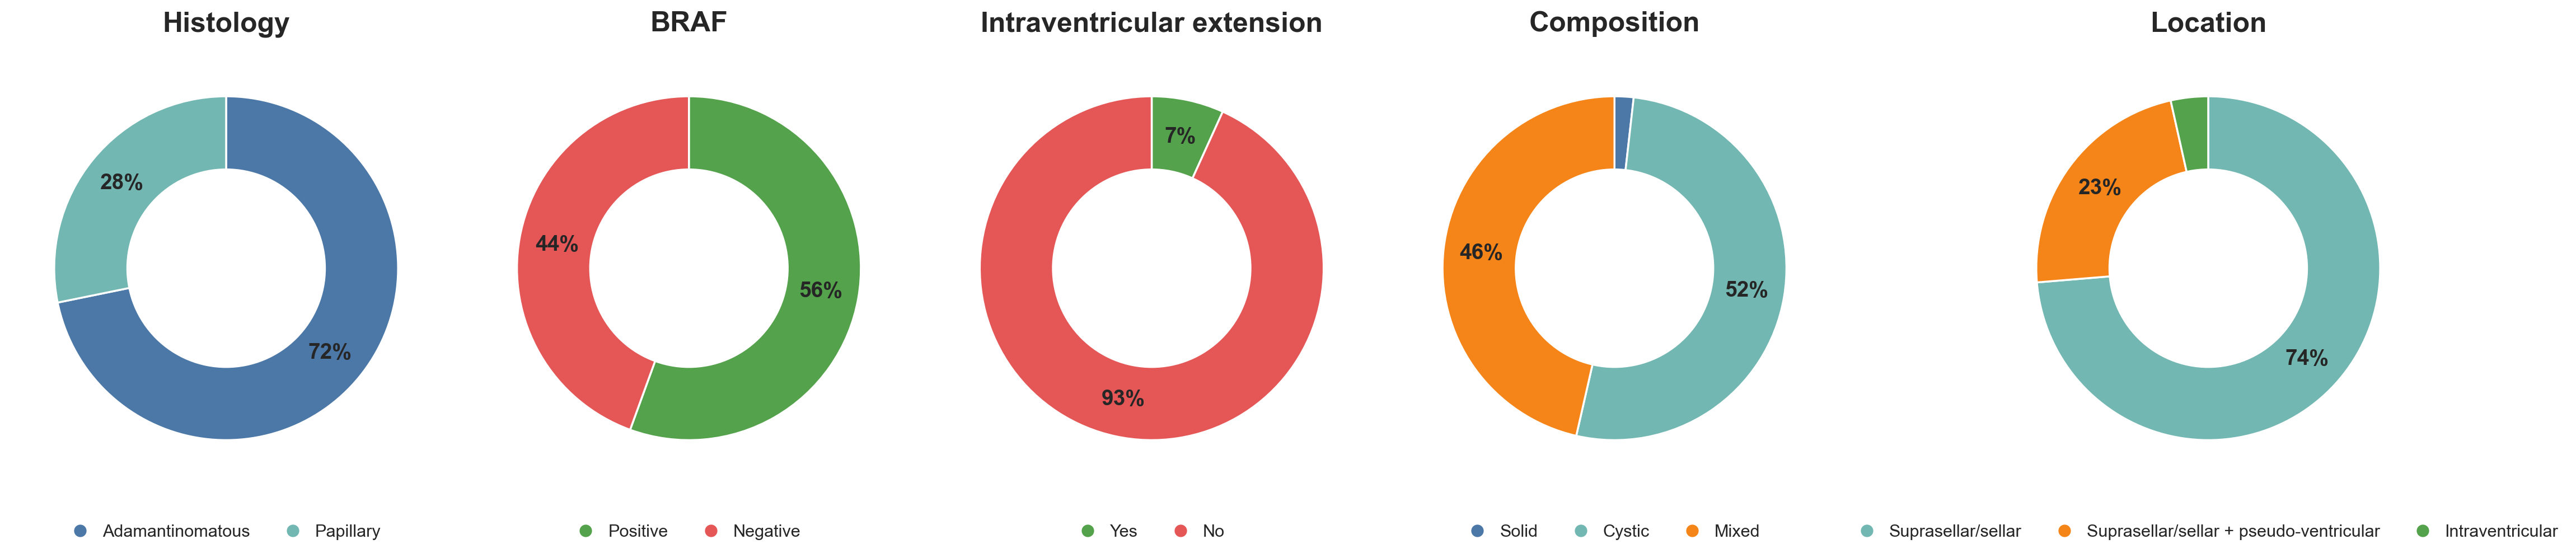

Saved: figs/fig_tumor_pathology_pies.png


In [12]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# ---------- config ----------
DATA = "data.csv"
OUT  = "figs/fig_tumor_pathology_pies.png"
os.makedirs("figs", exist_ok=True)

PALETTE = {
    "Adamantinomatous": "#4C78A8", "Papillary": "#72B7B2",
    "Positive": "#54A24B", "Negative": "#E45756",
    "Yes": "#54A24B", "No": "#E45756",
    "Solid": "#4C78A8", "Cystic": "#72B7B2", "Mixed": "#F58518",
    "Intrasellar": "#4C78A8", "Suprasellar/sellar": "#72B7B2",
    "Suprasellar/sellar + pseudo-ventricular": "#F58518",
    "Suprasellar/sellar + intraventricular": "#E45756",
    "Intraventricular": "#54A24B", "Other": "#B279A2",
}

def clean(s): 
    return s.astype(str).str.strip().str.lower()

def pct_counts(series, mapping=None, order=None, keep_top=None, group_other=True):
    s = series.dropna()
    if s.empty: return [], []
    s = clean(s)
    if mapping: s = s.replace(mapping)
    vc = s.value_counts(normalize=True) * 100
    if keep_top is not None and len(vc) > keep_top and group_other:
        top = vc.head(keep_top)
        other = vc.iloc[keep_top:].sum()
        vc = pd.concat([top, pd.Series({"Other": other})])
    if order: vc = vc.reindex(order).dropna()
    return vc.index.tolist(), vc.values.tolist()

def autopct_func(pct):  # hide tiny slice labels
    return f"{pct:.0f}%" if pct >= 5 else ""

def pie_with_local_legend(ax, labels, values, title):
    if not labels:
        ax.axis("off")
        ax.set_title(title, fontweight="bold", fontsize=16, pad=12)
        return None

    colors = [PALETTE.get(lbl, "#999999") for lbl in labels]
    wedges, texts, autotexts = ax.pie(
        values, labels=None, colors=colors,
        startangle=90, counterclock=False,
        autopct=autopct_func, pctdistance=0.78,
        wedgeprops={"edgecolor": "white", "linewidth": 1.25}
    )

    # Donut look
    centre = plt.Circle((0,0), 0.58, fc="white", ec="white", linewidth=0)
    ax.add_artist(centre)
    ax.set_aspect('equal')
    ax.set_title(title, fontweight="bold", fontsize=18, pad=14)

    for t in autotexts:
        t.set_fontsize(14)
        t.set_fontweight("bold")

    # Local legend (kept within layout box)
    handles = [Line2D([0],[0], marker='o', color='w',
                      label=l, markerfacecolor=c, markersize=9)
               for l, c in zip(labels, colors)]
    leg = ax.legend(
        handles=handles, loc="upper center",
        bbox_to_anchor=(0.5, -0.06),  # slightly below the pie
        frameon=False, ncol=min(len(labels), 4),
        fontsize=11, handlelength=1
    )
    return leg

# ---------- load ----------
df = pd.read_csv(DATA)

# Columns & mappings
hist_col = "Tumor (Adamantinomatous, papillary)"
braf_col = "BRAF+"
ivx_col  = "Intraventricular extension"
comp_col = "Solid, cystic, mixed"
loc_col  = ("Location (purely intrasellar, suprasellar/sellar, suprasellar/sellar "
            "with pseudoventricular extension, suprasellar/sellar with intraventricular extension, purely intraventricular)")

hist_map = {"adamantinomatous":"Adamantinomatous", "papillary":"Papillary",
            "adamantinomatous ":"Adamantinomatous", "papillary ":"Papillary"}
comp_map = {"solid":"Solid","cystic":"Cystic","mixed":"Mixed"}
loc_map  = {"purely intrasellar":"Intrasellar", "suprasellar/sellar":"Suprasellar/sellar",
            "suprasellar/sellar with pseudoventricular extension":"Suprasellar/sellar + pseudo-ventricular",
            "suprasellar/sellar with intraventricular extension":"Suprasellar/sellar + intraventricular",
            "purely intraventricular":"Intraventricular"}

# Prepare data for each pie
hist_labels, hist_vals = pct_counts(df[hist_col] if hist_col in df.columns else pd.Series(dtype=object),
                                    mapping=hist_map, order=["Adamantinomatous","Papillary"])

if braf_col in df.columns and df[braf_col].dropna().size:
    pos = (df[braf_col].dropna() == 1).mean()*100
    braf_labels, braf_vals = ["Positive","Negative"], [pos, 100-pos]
else:
    braf_labels, braf_vals = [], []

if ivx_col in df.columns and df[ivx_col].dropna().size:
    yes = (df[ivx_col].dropna() == 1).mean()*100
    ivx_labels, ivx_vals = ["Yes","No"], [yes, 100-yes]
else:
    ivx_labels, ivx_vals = [], []

comp_labels, comp_vals = pct_counts(df[comp_col] if comp_col in df.columns else pd.Series(dtype=object),
                                    mapping=comp_map, order=["Solid","Cystic","Mixed"])

loc_labels, loc_vals = pct_counts(df[loc_col] if loc_col in df.columns else pd.Series(dtype=object),
                                  mapping=loc_map, keep_top=4, group_other=True)

sets = [("Histology", hist_labels, hist_vals),
        ("BRAF", braf_labels, braf_vals),
        ("Intraventricular extension", ivx_labels, ivx_vals),
        ("Composition", comp_labels, comp_vals),
        ("Location", loc_labels, loc_vals)]
sets = [s for s in sets if len(s[1]) > 0]

# ---------- layout & draw ----------
n = len(sets)
cols = min(5, n)
rows = int(np.ceil(n/cols))

fig, axes = plt.subplots(
    rows, cols, figsize=(4.6*cols, 4.8*rows),
    constrained_layout=True, dpi=200
)

axes = np.atleast_1d(axes).flatten()
extra_artists = []
for ax, (title, labels, vals) in zip(axes, sets):
    leg = pie_with_local_legend(ax, labels, vals, title)
    if leg is not None:
        extra_artists.append(leg)

for ax in axes[len(sets):]:
    ax.axis("off")

# Save: tight bbox + include legends so nothing is cut
fig.savefig(
    OUT, bbox_inches="tight", pad_inches=0.25, facecolor="white",
    bbox_extra_artists=extra_artists
)
plt.show()
print(f"Saved: {OUT}")



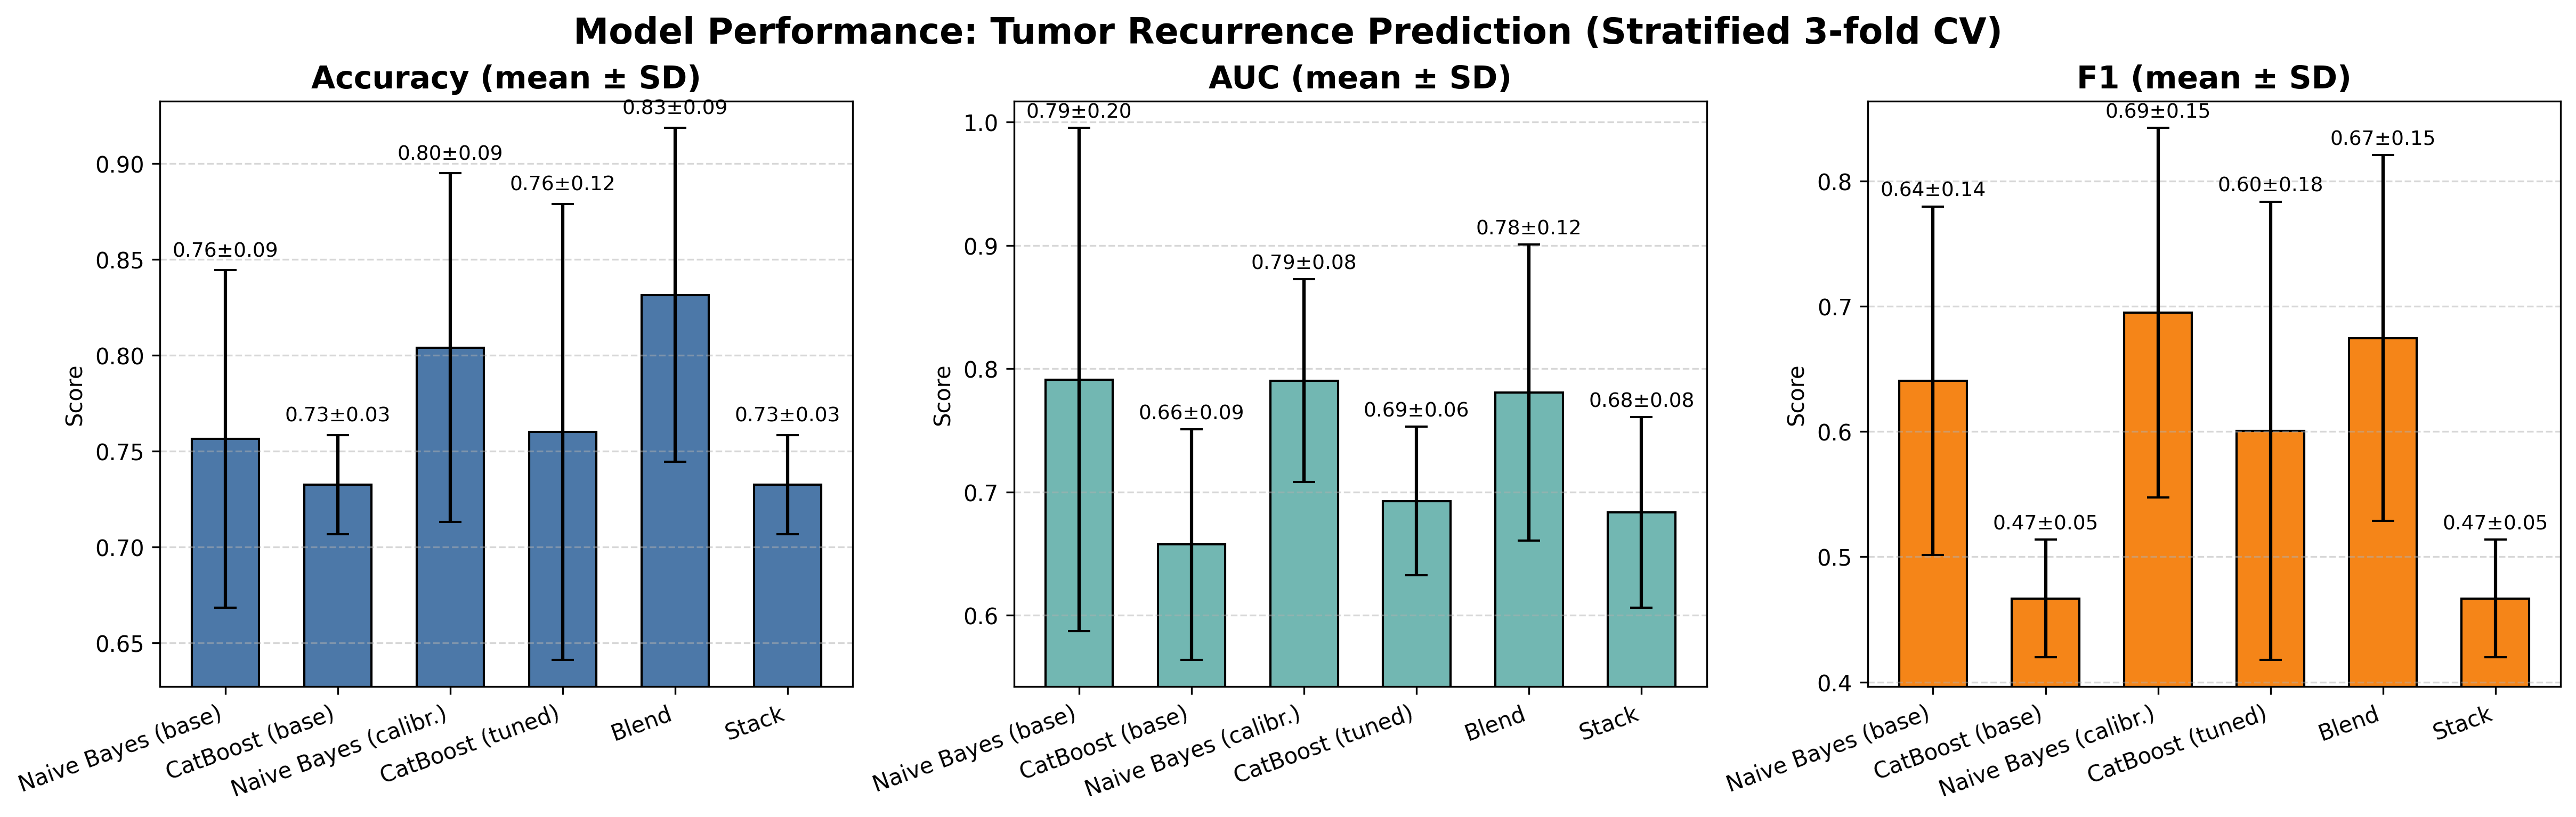

In [4]:
import os
import numpy as np
import matplotlib.pyplot as plt

os.makedirs("figs", exist_ok=True)

# -----------------------------
# Enter the cross-validated means ± SDs you reported
# -----------------------------
models = [
    "Ridge (base)",
    "CatBoost (base)",
    "Ridge (calibr.)",
    "CatBoost (tuned)",
    "Blend",
    "Stack"
]

ACC_mean = np.array([0.7491, 0.7051, 0.7253, 0.7527, 0.7491, 0.6996])
ACC_sd   = np.array([0.0407, 0.1484, 0.0324, 0.0838, 0.0407, 0.1260])

AUC_mean = np.array([0.7019, 0.5676, 0.6963, 0.6356, 0.7704, 0.7130])
AUC_sd   = np.array([0.0352, 0.0703, 0.0263, 0.1282, 0.0547, 0.0522])

F1_mean  = np.array([0.7990, 0.7967, 0.7912, 0.8347, 0.8114, 0.7534])
F1_sd    = np.array([0.0347, 0.0971, 0.0649, 0.0566, 0.0434, 0.1337])

models = [
    "Naive Bayes (base)",
    "CatBoost (base)",
    "Naive Bayes (calibr.)",
    "CatBoost (tuned)",
    "Blend",
    "Stack"
]

ACC_mean = np.array([0.7564, 0.7326, 0.8040, 0.7601, 0.8315, 0.7326]) 
ACC_sd   = np.array([0.0880, 0.0259, 0.0909, 0.1189, 0.0871, 0.0259]) 

AUC_mean = np.array([0.7912, 0.6574, 0.7903, 0.6926, 0.7806, 0.6833]) 
AUC_sd   = np.array([0.2041, 0.0936, 0.0824, 0.0602, 0.1199, 0.0773]) 

F1_mean  = np.array([0.6406, 0.4667, 0.6948, 0.6005, 0.6746, 0.4667]) 
F1_sd    = np.array([0.1390, 0.0471, 0.1476, 0.1829, 0.1459, 0.0471]) 

# -----------------------------
# Helper to make a tight, zoomed bar+error plot
# -----------------------------
def plot_metric(ax, title, means, sds, color="#4C78A8"):
    x = np.arange(len(models))
    ax.bar(x, means, yerr=sds, capsize=5, color=color, edgecolor="black", width=0.6)

    # Zoom y-axis to data range with small padding (avoid starting at 0)
    lo = float(np.min(means - sds))
    hi = float(np.max(means + sds))
    pad = max(0.01, 0.05 * (hi - lo))
    ax.set_ylim(lo - pad, hi + pad)

    for i, (m, sd) in enumerate(zip(means, sds)):
        ax.text(i, m + sd + 0.005, f"{m:.2f}±{sd:.02f}", ha="center", va="bottom", fontsize=9)

    ax.set_title(title, fontsize=14, fontweight="bold")
    ax.set_xticks(x)
    ax.set_xticklabels(models, rotation=20, ha="right")
    ax.grid(axis="y", linestyle="--", alpha=0.5)
    ax.set_ylabel("Score")

# -----------------------------
# Figure with 3 panels
# -----------------------------
fig, axes = plt.subplots(1, 3, figsize=(16, 5), constrained_layout=True, dpi=300)

plot_metric(axes[0], "Accuracy (mean ± SD)", ACC_mean, ACC_sd, color="#4C78A8")
plot_metric(axes[1], "AUC (mean ± SD)",      AUC_mean, AUC_sd, color="#72B7B2")
plot_metric(axes[2], "F1 (mean ± SD)",       F1_mean,  F1_sd,  color="#F58518")

fig.suptitle("Model Performance: Tumor Recurrence Prediction (Stratified 3-fold CV)", fontsize=16, fontweight="bold")
plt.savefig("figs/fig_model_performance_bars.png", dpi=300)
plt.show()




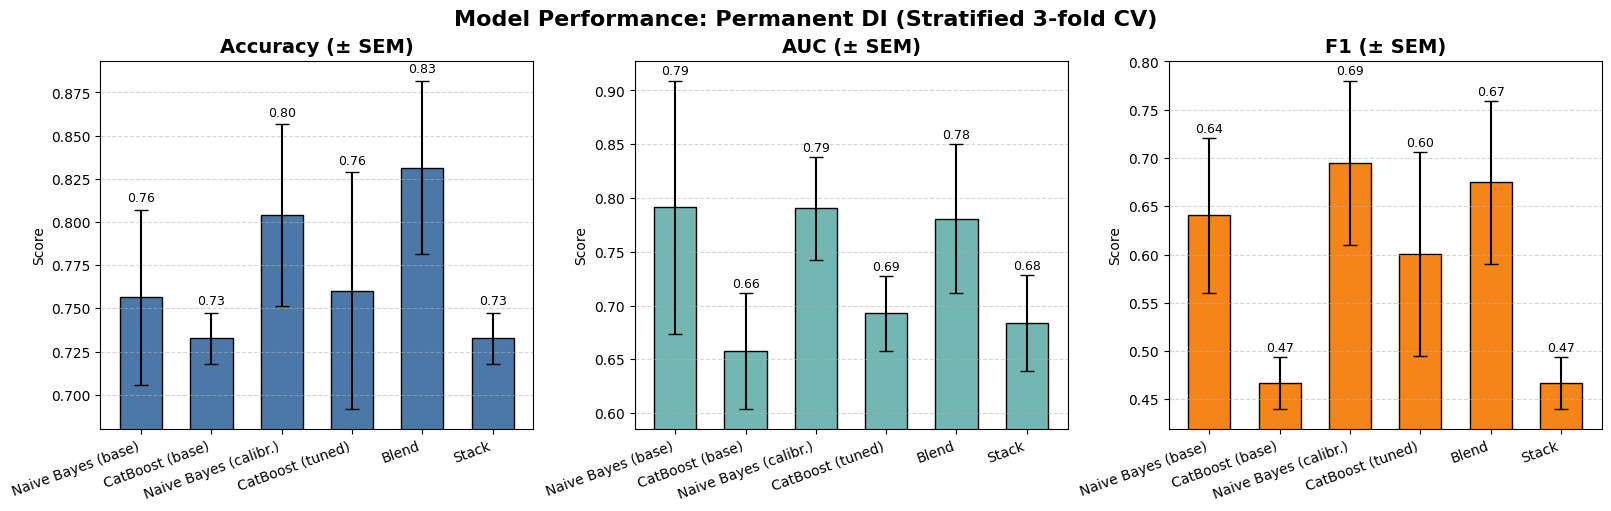

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
from math import sqrt

os.makedirs("figs", exist_ok=True)

# -----------------------------
# CV means ± SD (your numbers)
# -----------------------------
models = [
    "Naive Bayes (base)",
    "CatBoost (base)",
    "Naive Bayes (calibr.)",
    "CatBoost (tuned)",
    "Blend",
    "Stack"
]

ACC_mean = np.array([0.7491, 0.7051, 0.7253, 0.7527, 0.7491, 0.6996])
ACC_sd   = np.array([0.0407, 0.1484, 0.0324, 0.0838, 0.0407, 0.1260])

AUC_mean = np.array([0.7019, 0.5676, 0.6963, 0.6356, 0.7704, 0.7130])
AUC_sd   = np.array([0.0352, 0.0703, 0.0263, 0.1282, 0.0547, 0.0522])

F1_mean  = np.array([0.7990, 0.7967, 0.7912, 0.8347, 0.8114, 0.7534])
F1_sd    = np.array([0.0347, 0.0971, 0.0649, 0.0566, 0.0434, 0.1337])



# -----------------------------
# Choose error bar mode here:
#   "sd"  -> plot SD (what you had)
#   "sem" -> plot SD/sqrt(k)
#   "ci95"-> plot 95% CI = t_(0.975, df=k-1)* SD/sqrt(k)   (t for k=3 is 4.303)
# -----------------------------
ERR_MODE = "sem"   # <- change to "sd" or "ci95" if you prefer
K = 3              # stratified 3-fold CV
t_crit = 4.303     # two-sided 95% t for df=2

def make_errors(sd):
    if ERR_MODE == "sd":
        return sd, "± SD"
    elif ERR_MODE == "sem":
        return sd / sqrt(K), "± SEM"
    elif ERR_MODE == "ci95":
        return t_crit * sd / sqrt(K), "95% CI"
    else:
        raise ValueError("ERR_MODE must be one of: 'sd', 'sem', 'ci95'")

ACC_err, acc_label = make_errors(ACC_sd)
AUC_err, auc_label = make_errors(AUC_sd)
F1_err,  f1_label  = make_errors(F1_sd)

# -----------------------------
# Helper to make a tight, zoomed bar+error plot
# -----------------------------
def plot_metric(ax, title, means, errs, color="#4C78A8"):
    x = np.arange(len(models))
    ax.bar(x, means, yerr=errs, capsize=5, color=color, edgecolor="black", width=0.6)

    # Zoom y-axis to data range with small padding (avoid starting at 0)
    lo = float(np.min(means - errs))
    hi = float(np.max(means + errs))
    pad = max(0.01, 0.06 * (hi - lo))
    ax.set_ylim(lo - pad, hi + pad)

    for i, (m, e) in enumerate(zip(means, errs)):
        ax.text(i, m + e + 0.003, f"{m:.2f}", ha="center", va="bottom", fontsize=9)

    ax.set_title(title, fontsize=14, fontweight="bold")
    ax.set_xticks(x)
    ax.set_xticklabels(models, rotation=20, ha="right")
    ax.grid(axis="y", linestyle="--", alpha=0.5)
    ax.set_ylabel("Score")

# -----------------------------
# Figure with 3 panels
# -----------------------------
fig, axes = plt.subplots(1, 3, figsize=(16, 5), constrained_layout=True)

plot_metric(axes[0], f"Accuracy ({acc_label})", ACC_mean, ACC_err, color="#4C78A8")
plot_metric(axes[1], f"AUC ({auc_label})",      AUC_mean, AUC_err, color="#72B7B2")
plot_metric(axes[2], f"F1 ({f1_label})",        F1_mean,  F1_err,  color="#F58518")

fig.suptitle("Model Performance: Permanent DI (Stratified 3-fold CV)", fontsize=16, fontweight="bold")
plt.savefig(f"figs/fig_model_performance_{ERR_MODE}.png", dpi=300)
plt.show()


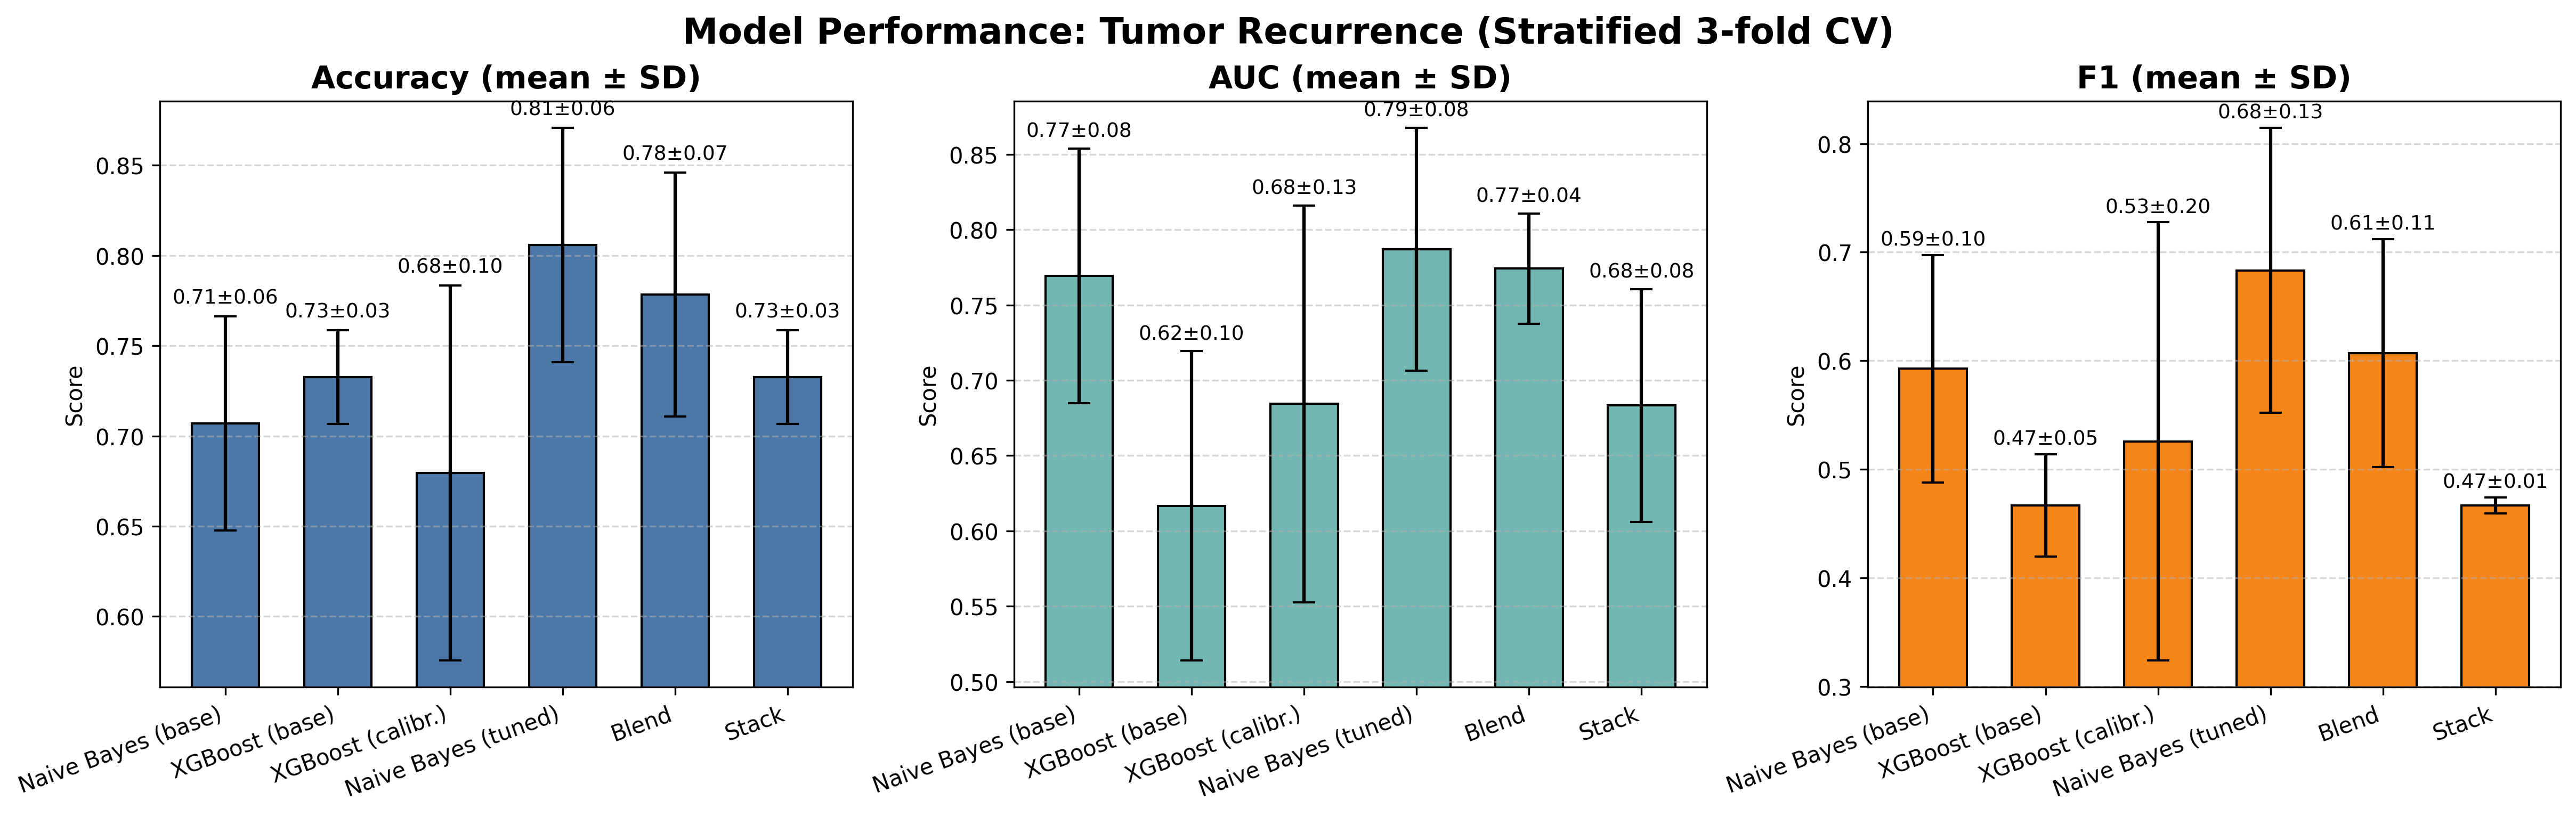

In [12]:
import os
import numpy as np
import matplotlib.pyplot as plt

os.makedirs("figs", exist_ok=True)

# -----------------------------
# Enter the cross-validated means ± SDs you reported
# -----------------------------
models = [
    "Naive Bayes (base)",
    "XGBoost (base)",
    "XGBoost (calibr.)",
    "Naive Bayes (tuned)",
    "Blend",
    "Stack"
]
ACC_mean = np.array([0.7070, 0.7326, 0.6795, 0.8059, 0.7784, 0.7326])
AUC_mean = np.array([0.7694, 0.6167, 0.6843, 0.7870, 0.7741, 0.6833])
F1_mean  = np.array([0.5926, 0.4667, 0.5258, 0.6833, 0.6071, 0.4667])

# Standard deviations
ACC_sd = np.array([0.0592, 0.0259, 0.1039, 0.0649, 0.0675, 0.0259])
AUC_sd = np.array([0.0845, 0.1027, 0.1317, 0.0806, 0.0367, 0.0773])
F1_sd  = np.array([0.1048, 0.0471, 0.2018, 0.1312, 0.1051, 0.0074])

# -----------------------------
# Helper to make a tight, zoomed bar+error plot
# -----------------------------
def plot_metric(ax, title, means, sds, color="#4C78A8"):
    x = np.arange(len(models))
    ax.bar(x, means, yerr=sds, capsize=5, color=color, edgecolor="black", width=0.6)

    # Zoom y-axis to data range with small padding (avoid starting at 0)
    lo = float(np.min(means - sds))
    hi = float(np.max(means + sds))
    pad = max(0.01, 0.05 * (hi - lo))
    ax.set_ylim(lo - pad, hi + pad)

    for i, (m, sd) in enumerate(zip(means, sds)):
        ax.text(i, m + sd + 0.005, f"{m:.2f}±{sd:.02f}", ha="center", va="bottom", fontsize=9)

    ax.set_title(title, fontsize=14, fontweight="bold")
    ax.set_xticks(x)
    ax.set_xticklabels(models, rotation=20, ha="right")
    ax.grid(axis="y", linestyle="--", alpha=0.5)
    ax.set_ylabel("Score")

# -----------------------------
# Figure with 3 panels
# -----------------------------
fig, axes = plt.subplots(1, 3, figsize=(16, 5), constrained_layout=True, dpi=300)

plot_metric(axes[0], "Accuracy (mean ± SD)", ACC_mean, ACC_sd, color="#4C78A8")
plot_metric(axes[1], "AUC (mean ± SD)",      AUC_mean, AUC_sd, color="#72B7B2")
plot_metric(axes[2], "F1 (mean ± SD)",       F1_mean,  F1_sd,  color="#F58518")

fig.suptitle("Model Performance: Tumor Recurrence (Stratified 3-fold CV)", fontsize=16, fontweight="bold")
plt.savefig("figs/fig_model_performance_bars.png", dpi=300)
plt.show()


